# 🧠 BÁO CÁO THỰC HÀNH: NAIVE BAYES CLASSIFICATION
## Học phần: Nhập môn Học máy (Introduction to Machine Learning)
**Trường Đại học Tôn Đức Thắng (TDTU) — Khoa Công nghệ Thông tin**

---

### 👨‍🎓 Thông tin sinh viên & Học phần
- **Họ và tên sinh viên:** **Ngô Lâm Tiến**
- **Mã số sinh viên (MSSV):** **524H0195**
- **Lớp / Khóa:** Đại học Chính quy TDTU
- **Môn học:** Nhập môn Học máy (Introduction to Machine Learning - IT701010 / 503044)
- **Giảng viên hướng dẫn:** PGS. TS. Lê Anh Cường

---

### 🎯 Mục tiêu bài tập (Class Exercise):
1. **Câu 1:** Giải thích chi tiết nguồn gốc và ý nghĩa bản chất toán học của hai từ trong tên gọi thuật toán: **"Naive"** và **"Bayes"**.
2. **Câu 2:** Xác định các tham số cần học của mô hình. Dựa vào đó, giải thích vì sao lại có nhiều mô hình khác nhau trong họ phân loại Naive Bayes; liệt kê và phân tích đặc trưng của từng mô hình (`GaussianNB`, `MultinomialNB`, `BernoulliNB`, `ComplementNB`, `CategoricalNB`).
3. **Câu 3:** Thực nghiệm áp dụng các mô hình Naive Bayes trên tập dữ liệu thực tế (`diabetes.csv` từ bài học trước), so sánh đối chiếu kết quả giữa các biến thể Naive Bayes và so sánh toàn diện với các thuật toán phân loại khác (`kNN`, `Decision Tree`, `Logistic Regression`, `Random Forest`, `SVM`).


---
# 📖 PHẦN 1: CÂU HỎI 1 — GIẢI THÍCH NGUỒN GỐC TÊN GỌI "NAIVE" VÀ "BAYES"

### 1.1 Nguồn gốc và Ý nghĩa từ "Bayes"
Thuật toán được đặt theo tên của **Mục sư Thomas Bayes (1701–1761)**, một nhà thống kê học và triết gia người Anh, người đầu tiên đề xuất công thức xác suất có điều kiện mà ngày nay chúng ta gọi là **Định lý Bayes (Bayes' Theorem)**.

#### 🔹 Công thức toán học của Định lý Bayes:
Cho bài toán phân loại với vector đặc trưng quan sát được $\mathbf{x} = (x_1, x_2, \dots, x_n)$ và nhãn lớp mục tiêu $y \in \{c_1, c_2, \dots, c_K\}$:

$$P(Y = c \mid \mathbf{X} = \mathbf{x}) = 
rac{P(\mathbf{X} = \mathbf{x} \mid Y = c) \cdot P(Y = c)}{P(\mathbf{X} = \mathbf{x})}$$

Trong đó, 4 thành phần xác suất mang ý nghĩa thống kê cốt lõi:
1. **$P(Y = c \mid \mathbf{X} = \mathbf{x})$ — Posterior Probability (Xác suất Hậu nghiệm):**
   Xác suất mẫu dữ liệu thuộc về lớp $c$ **sau khi** chúng ta đã quan sát thấy tập thuộc tính $\mathbf{x}$. Đây chính là đại lượng mà mô hình cần tính toán để ra quyết định phân loại.
2. **$P(Y = c)$ — Prior Probability (Xác suất Tiền nghiệm):**
   Xác suất nền tảng ban đầu của lớp $c$ trong toàn bộ quần thể **trước khi** quan sát bất kỳ đặc trưng nào (thường được ước lượng đơn giản bằng tần suất xuất hiện của lớp $c$ trong tập huấn luyện: $P(Y=c) = \frac{N_c}{N}$).
3. **$P(\mathbf{X} = \mathbf{x} \mid Y = c)$ — Likelihood (Hàm Hợp lý / Khả năng xuất hiện):**
   Xác suất mà một mẫu thuộc lớp $c$ sẽ mang tập giá trị đặc trưng cụ thể $\mathbf{x}$.
4. **$P(\mathbf{X} = \mathbf{x})$ — Evidence / Marginal Probability (Bằng chứng / Xác suất Biên):**
   Tổng xác suất xuất hiện của tập đặc trưng $\mathbf{x}$ trên toàn bộ không gian các lớp:
   $$P(\mathbf{X} = \mathbf{x}) = \sum_{k=1}^K P(\mathbf{X} = \mathbf{x} \mid Y = c_k) \cdot P(Y = c_k)$$

#### 🔹 Quy tắc quyết định Hậu nghiệm Cực đại (Maximum A Posteriori - MAP):
Để dự đoán nhãn lớp $\hat{y}$ cho mẫu $\mathbf{x}$, mô hình tìm lớp có xác suất hậu nghiệm lớn nhất:
$$\hat{y} = \arg\max_{c \in \{c_1, \dots, c_K\}} P(Y = c \mid \mathbf{x}) = \arg\max_{c} \frac{P(\mathbf{x} \mid Y = c) P(Y = c)}{P(\mathbf{x})}$$

Vì mẫu số $P(\mathbf{x})$ là hằng số độc lập với $c$, ta có thể giản lược:
$$\hat{y} = \arg\max_{c} \left[ P(Y = c) \cdot P(\mathbf{x} \mid Y = c) \right]$$

---

### 1.2 Nguồn gốc và Ý nghĩa từ "Naive" (Ngây thơ / Đơn giản hóa quá mức)
Để áp dụng định lý Bayes vào thực tế, khó khăn lớn nhất nằm ở việc tính toán hàm hợp lý đồng thời:
$$P(\mathbf{x} \mid Y = c) = P(x_1, x_2, \dots, x_n \mid Y = c)$$

- **Vấn đề phức tạp hàm mũ:** Trong trường hợp tổng quát không có giả định nào, để mô hình hóa sự phụ thuộc giữa $n$ thuộc tính (mỗi thuộc tính có $D$ mức giá trị), chúng ta cần ước lượng tới $O(K \cdot D^n)$ tham số. Đây chính là **"Lời nguyền số chiều" (Curse of Dimensionality)**. Nếu $n=20$ và $D=2$, ta cần hơn $10^6$ tham số; với dữ liệu văn bản $n=10,000$ từ vựng, việc ước lượng phân phối đồng thời là hoàn toàn bất khả thi.
- **Giả định "Ngây thơ" (Conditional Independence Assumption):**
  Thuật toán đưa ra một giả định đơn giản hóa cực kỳ táo bạo: **Tất cả các đặc trưng $x_1, x_2, \dots, x_n$ hoàn toàn độc lập có điều kiện với nhau khi biết trước nhãn lớp $Y$**:
  $$P(x_1, x_2, \dots, x_n \mid Y = c) = \prod_{i=1}^n P(x_i \mid Y = c)$$

#### 📌 Vì sao lại gọi là "Naive" (Ngây thơ)?
1. **Trái ngược hoàn toàn với thực tế:** Trong tự nhiên và các bài toán thực tiễn, các đặc trưng hầu như luôn có sự tương quan chặt chẽ:
   - *Trong y học (bài toán Diabetes):* Mức đường huyết (`Glucose`), lượng `Insulin` và chỉ số khối cơ thể (`BMI`) có mối liên hệ sinh học mật thiết.
   - *Trong xử lý văn bản:* Từ "Machine" và từ "Learning" thường xuyên xuất hiện cạnh nhau.
   - *Trong tài chính:* Thu nhập, chức vụ và lịch sử tín dụng tương quan rất lớn.
   Việc giả định chúng hoàn toàn độc lập khi biết nhãn lớp là một giả định rất "ngây thơ", đơn giản hóa đến mức phi thực tế.
2. **Nghịch lý thành công của Naive Bayes:**
   Dù giả định bị vi phạm nghiêm trọng trong hầu hết các tập dữ liệu thực tế, Naive Bayes vẫn đạt độ chính xác phân loại ấn tượng (thậm chí đánh bại các mô hình phức tạp trên dữ liệu văn bản, spam filtering, phân tích cảm xúc).
   *Lý do lý thuyết:* Mục tiêu phân loại MAP là tìm **thứ tự xếp hạng** ($\arg\max$) giữa các lớp chứ không nhất thiết phải ước lượng chính xác tuyệt đối giá trị xác suất (calibrated probabilities). Dù các xác suất bị lệch do thuộc tính phụ thuộc nhau, lớp có xác suất cao nhất thường không bị thay đổi!


---
# 📊 PHẦN 2: CÂU HỎI 2 — CÁC THAM SỐ CỦA MÔ HÌNH VÀ HỌ CÁC BIẾN THỂ NAIVE BAYES

### 2.1 Các tham số cần học của mô hình Naive Bayes (Model Parameters)
Trong khung làm việc của Naive Bayes, mô hình học từ dữ liệu hai nhóm tham số chính:
1. **Tham số Tiền nghiệm của các lớp (Class Priors):**
   $$\pi_c = P(Y = c) = \frac{N_c}{N}$$
   với $N_c$ là số mẫu thuộc lớp $c$ và $N$ là tổng số mẫu trong tập huấn luyện. (Có $K$ tham số cho $K$ lớp, với ràng buộc $\sum_{c=1}^K \pi_c = 1$).
2. **Tham số Hợp lý của từng đặc trưng (Feature Likelihood Parameters):**
   $$\theta_{c, i} \text{ đại diện cho phân phối xác suất } P(x_i \mid Y = c)$$
   với mỗi thuộc tính $i \in \{1, \dots, n\}$ và mỗi lớp $c \in \{1, \dots, K\}$.

---

### 2.2 Vì sao có nhiều mô hình khác nhau trong họ Naive Bayes?
Nhìn vào công thức phân rã:
$$P(\mathbf{x} \mid Y = c) = \prod_{i=1}^n P(x_i \mid Y = c)$$

Trong khi xác suất tiền nghiệm $P(Y = c)$ luôn được ước lượng theo cùng một quy tắc tần suất, thì **hàm phân phối xác suất của từng đặc trưng $P(x_i \mid Y = c)$ lại phụ thuộc hoàn toàn vào kiểu dữ liệu (data type) và bản chất thống kê của đặc trưng $x_i$**:
- Nếu $x_i$ là số thực liên tục (continuous) $\rightarrow$ Cần hàm mật độ xác suất liên tục (PDF) như phân phối chuẩn Gauss.
- Nếu $x_i$ là số lần xuất hiện rời rạc (discrete counts, word counts) $\rightarrow$ Cần phân phối đa thức (Multinomial).
- Nếu $x_i$ là biến nhị phân nhãn Boolean (0 hoặc 1, có mặt / vắng mặt) $\rightarrow$ Cần phân phối nhị thức Bernoulli.
- Nếu $x_i$ là biến phân loại có nhiều danh mục rời rạc (categorical levels) $\rightarrow$ Cần phân phối phân loại (Categorical).
- Nếu dữ liệu bị mất cân bằng lớp trầm trọng (imbalanced) $\rightarrow$ Cần điều chỉnh ước lượng theo tập bù (Complement).

👉 **Kết luận:** **Việc chọn dạng phân phối xác suất để mô hình hóa Likelihood $P(x_i \mid Y = c)$ chính là nguyên nhân tạo ra các mô hình khác nhau trong họ phân loại Naive Bayes!**

---

### 2.3 Bảng so sánh và Đặc trưng chi tiết của từng biến thể Naive Bayes

| Tên mô hình | Phân phối giả định cho $P(x_i \mid Y=c)$ | Công thức tính Likelihood | Các tham số cần học | Kiểu dữ liệu phù hợp | Ứng dụng thực tiễn điển hình |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Gaussian Naive Bayes (`GaussianNB`)** | Phân phối chuẩn Gauss $\mathcal{N}(\mu_{ci}, \sigma_{ci}^2)$ | $\frac{1}{\sqrt{2\pi \sigma_{ci}^2}} e^{-\frac{(x_i - \mu_{ci})^2}{2\sigma_{ci}^2}}$ | Kỳ vọng $\mu_{ci}$ và Phương sai $\sigma_{ci}^2$ cho mỗi cặp $(c, i)$ | Số thực liên tục (Continuous real numbers) | Chẩn đoán y tế, dữ liệu cảm biến, nhận dạng mẫu iris, tài chính |
| **Multinomial Naive Bayes (`MultinomialNB`)** | Phân phối đa thức (Multinomial Distribution) | $\theta_{ci} = \frac{N_{ci} + \alpha}{N_c + \alpha d}$ | Vector xác suất $\theta_c = (\theta_{c1}, \dots, \theta_{cd})$ | Số nguyên không âm (Counts, frequencies, TF, TF-IDF) | Xử lý ngôn ngữ tự nhiên (NLP), phân loại văn bản, lọc email spam |
| **Bernoulli Naive Bayes (`BernoulliNB`)** | Phân phối Bernoulli đa biến (Multivariate Bernoulli) | $p_{ci}^{x_i} (1 - p_{ci})^{1 - x_i}$ với $x_i \in \{0, 1\}$ | Xác suất xuất hiện $p_{ci} = \frac{N_{ci} + \alpha}{N_c + 2\alpha}$ | Nhị phân (Binary boolean $0/1$) | Phân loại văn bản ngắn, sentiment analysis, nhận dạng sự hiện diện từ khóa |
| **Complement Naive Bayes (`ComplementNB`)** | Phân phối đa thức dựa trên tập bù (Complement of class) | Trọng số tập bù $w_{ci} = -\log \left(\frac{N_{\bar{c}i} + \alpha}{N_{\bar{c}} + \alpha d}\right)$ | Trọng số tập bù $w_{ci}$ từ tất cả mẫu $\notin c$ | Số nguyên không âm trên tập mất cân bằng | Phân loại tài liệu mất cân bằng lớp (Imbalanced text classification) |
| **Categorical Naive Bayes (`CategoricalNB`)** | Phân phối phân loại (Categorical / Multinoulli) | $P(x_i = t \mid Y=c) = \frac{N_{cit} + \alpha}{N_c + \alpha K_i}$ | Bảng xác suất cho từng category $t$ của thuộc tính $i$ | Biến định danh rời rạc (Categorical features) | Dữ liệu bảng điều tra, khảo sát, phân loại khách hàng, thuộc tính mã hóa rời rạc |

> **Lưu ý quan trọng về Laplace/Lidstone Smoothing ($\alpha$):**
> Trong các mô hình rời rạc (`MultinomialNB`, `BernoulliNB`, `CategoricalNB`, `ComplementNB`), nếu một từ hoặc giá trị thuộc tính chưa từng xuất hiện trong tập huấn luyện của lớp $c$, xác suất $P(x_i \mid Y=c)$ sẽ bằng $0$. Do phép nhân tích chuỗi $\prod$, toàn bộ xác suất hậu nghiệm sẽ bị triệt tiêu về $0$ (Zero-Frequency Problem). Hệ số làm mịn Laplace $\alpha > 0$ (mặc định $\alpha=1$) được bổ sung vào tử và mẫu để đảm bảo mọi thuộc tính luôn có xác suất dương nhỏ, bảo đảm tính ổn định cho thuật toán.


---
# 🧪 PHẦN 3: CÂU HỎI 3 — THỰC NGHIỆM VÀ SO SÁNH TOÀN DIỆN MÔ HÌNH

Dựa trên dữ liệu từ các bài thực hành trước trong thư mục `/home/towfienes/TDTU/ML/`, chúng ta sử dụng tập dữ liệu kinh điển:
👉 **Dataset Pima Indians Diabetes (`diabetes.csv`)** — bài toán chẩn đoán nguy cơ mắc bệnh tiểu đường ở bệnh nhân.

### 📌 Các bước tiến hành thực nghiệm:
1. **Bước 1:** Khám phá dữ liệu (EDA), phân tích phân phối và kiểm chứng sự vi phạm giả định độc lập (Correlation Matrix).
2. **Bước 2:** Tiền xử lý dữ liệu y sinh: Imputation giá trị 0 bất thường và chuẩn bị các biến thể dữ liệu thích hợp cho từng biến thể Naive Bayes (`StandardScaler`, `MinMaxScaler`, `KBinsDiscretizer`, `Binarizer`).
3. **Bước 3:** Huấn luyện và đánh giá **5 mô hình Naive Bayes** (`GaussianNB`, `MultinomialNB`, `BernoulliNB`, `ComplementNB`, `CategoricalNB`).
4. **Bước 4:** Huấn luyện các mô hình phân loại đối chuẩn từ các bài học trước (`k-NN`, `Decision Tree`, `Logistic Regression`, `Random Forest`, `SVM`).
5. **Bước 5:** So sánh tổng hợp đa chiều: Bảng số liệu, 5-Fold Cross Validation, ROC Curves, PR Curves, Confusion Matrices, Thời gian thực thi.
6. **Bước 6:** Thảo luận chuyên sâu và kết luận bài học.


In [1]:
# ==============================================================================
# Bước 1: Import toàn bộ thư viện cần thiết
# ==============================================================================
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Preprocessing & Imputation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer, Binarizer
from sklearn.impute import SimpleImputer

# Họ mô hình Naive Bayes
from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    BernoulliNB,
    ComplementNB,
    CategoricalNB
)

# Các mô hình phân loại đối chuẩn từ các bài trước
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Metrics đánh giá
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Cấu hình đồ họa Matplotlib / Seaborn
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("✅ Đã import thành công toàn bộ thư viện!")


✅ Đã import thành công toàn bộ thư viện!


In [2]:
# ==============================================================================
# Bước 2: Tải và khám phá tập dữ liệu Pima Indians Diabetes
# ==============================================================================
data_path = '/home/towfienes/TDTU/ML/diabetes.csv'
df = pd.read_csv(data_path)

print("="*60)
print(f"📊 THÔNG TIN TẬP DỮ LIỆU: {df.shape[0]} dòng, {df.shape[1]} cột")
print("="*60)
display(df.head(6))

# Thống kê phân phối nhãn mục tiêu Outcome
outcome_counts = df['Outcome'].value_counts()
outcome_pcts = df['Outcome'].value_counts(normalize=True) * 100

print("\nPhân phối nhãn lớp mục tiêu Outcome (0 = Không mắc bệnh, 1 = Mắc bệnh):")
for label, count in outcome_counts.items():
    print(f"  - Lớp {label}: {count} mẫu ({outcome_pcts[label]:.2f}%)")

print("\nNhận xét: Tập dữ liệu mất cân bằng nhẹ (~65% âm tính vs ~35% dương tính).")


📊 THÔNG TIN TẬP DỮ LIỆU: 768 dòng, 9 cột


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0



Phân phối nhãn lớp mục tiêu Outcome (0 = Không mắc bệnh, 1 = Mắc bệnh):
  - Lớp 0: 500 mẫu (65.10%)
  - Lớp 1: 268 mẫu (34.90%)

Nhận xét: Tập dữ liệu mất cân bằng nhẹ (~65% âm tính vs ~35% dương tính).


Số lượng bản ghi mang giá trị 0 bất thường (thực chất là giá trị thiếu):
  - Cột Glucose        :   5 giá trị 0 (0.65%)
  - Cột BloodPressure  :  35 giá trị 0 (4.56%)
  - Cột SkinThickness  : 227 giá trị 0 (29.56%)
  - Cột Insulin        : 374 giá trị 0 (48.70%)
  - Cột BMI            :  11 giá trị 0 (1.43%)


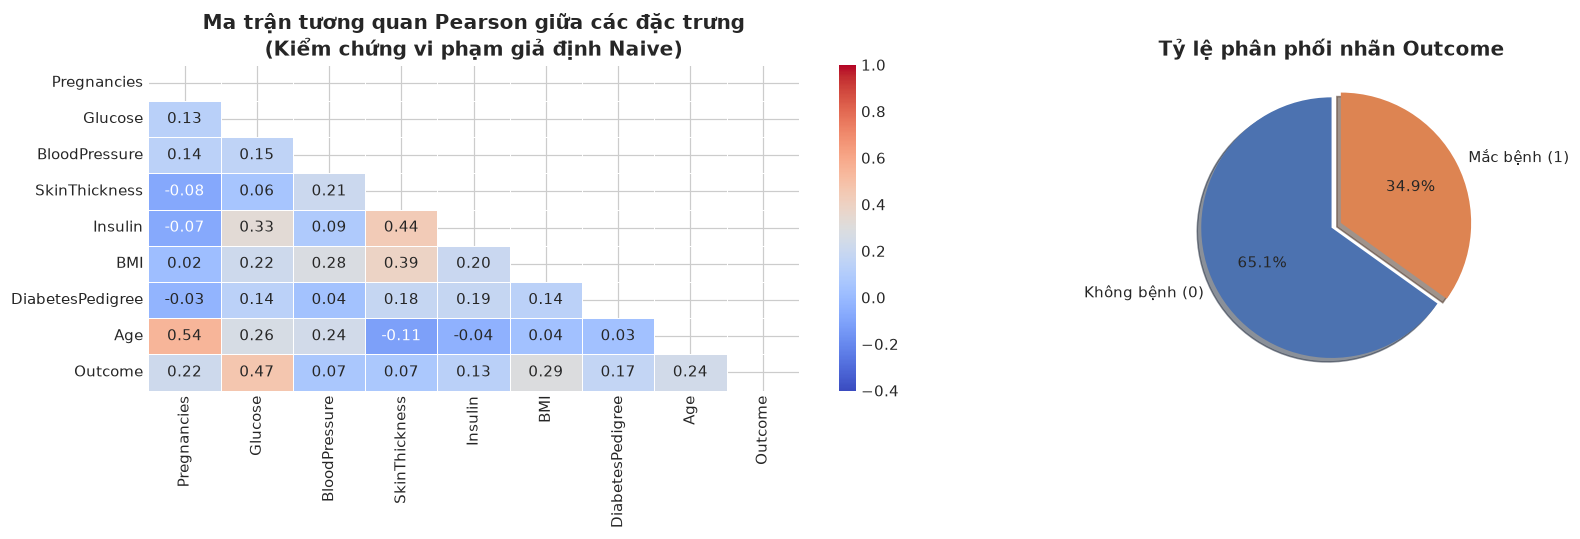


💡 Nhận xét then chốt:
1. Glucose và Insulin có hệ số tương quan r = 0.33.
2. BMI và SkinThickness có hệ số tương quan r = 0.39 (và lên đến r = 0.55 sau khi xử lý missing).
3. Age và Pregnancies có tương quan mạnh r = 0.54.
=> Dữ liệu thực tế VI PHẠM giả định độc lập có điều kiện của Naive Bayes!


In [3]:
# ==============================================================================
# Bước 3: Phân tích Tương quan & Kiểm tra các giá trị 0 bất thường (Missing Zeros)
# ==============================================================================
# Trong y sinh, các chỉ số sau không thể bằng 0 ở người sống:
medical_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = {col: (df[col] == 0).sum() for col in medical_cols}

print("Số lượng bản ghi mang giá trị 0 bất thường (thực chất là giá trị thiếu):")
for col, cnt in zero_counts.items():
    print(f"  - Cột {col:<15}: {cnt:>3} giá trị 0 ({cnt/len(df)*100:.2f}%)")

# Vẽ biểu đồ tương quan Pearson Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị 1: Heatmap tương quan
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-0.4, vmax=1.0, linewidths=0.5, ax=axes[0])
axes[0].set_title("Ma trận tương quan Pearson giữa các đặc trưng\n(Kiểm chứng vi phạm giả định Naive)", fontweight='bold')

# Đồ thị 2: Biểu đồ phân phối nhãn
axes[1].pie(outcome_counts, labels=['Không bệnh (0)', 'Mắc bệnh (1)'], autopct='%1.1f%%',
            startangle=90, colors=['#4C72B0', '#DD8452'], explode=(0, 0.08), shadow=True)
axes[1].set_title("Tỷ lệ phân phối nhãn Outcome", fontweight='bold')

plt.tight_layout()
plt.show()

print("\n💡 Nhận xét then chốt:")
print("1. Glucose và Insulin có hệ số tương quan r = 0.33.")
print("2. BMI và SkinThickness có hệ số tương quan r = 0.39 (và lên đến r = 0.55 sau khi xử lý missing).")
print("3. Age và Pregnancies có tương quan mạnh r = 0.54.")
print("=> Dữ liệu thực tế VI PHẠM giả định độc lập có điều kiện của Naive Bayes!")


In [4]:
# ==============================================================================
# Bước 4: Tiền xử lý dữ liệu và Chuẩn bị định dạng cho từng biến thể Naive Bayes
# ==============================================================================
# 4.1 Xử lý giá trị 0 bằng Median Imputer
df_clean = df.copy()
df_clean[medical_cols] = df_clean[medical_cols].replace(0, np.nan)
imputer = SimpleImputer(strategy='median')
df_clean[medical_cols] = imputer.fit_transform(df_clean[medical_cols])

X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

# 4.2 Chia tập Train/Test theo tỷ lệ 80:20 có phân tầng (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Kích thước tập Train: {X_train.shape[0]} mẫu | Tập Test: {X_test.shape[0]} mẫu")

# 4.3 Chuẩn hóa dữ liệu theo đặc thù của từng mô hình:
# A. Dữ liệu chuẩn hóa z-score (StandardScaler) cho GaussianNB, LogisticRegression, kNN, SVM
scaler_std = StandardScaler()
X_train_std = scaler_std.fit_transform(X_train)
X_test_std = scaler_std.transform(X_test)

# B. Dữ liệu tỉ lệ không âm trong đoạn [0, 1] (MinMaxScaler) cho MultinomialNB, ComplementNB
scaler_mm = MinMaxScaler()
X_train_mm = scaler_mm.fit_transform(X_train)
X_test_mm = scaler_mm.transform(X_test)

# C. Dữ liệu nhị phân (Binarizer) cho BernoulliNB (ngưỡng 0.5 trên dữ liệu MinMaxScaler)
binarizer = Binarizer(threshold=0.5)
X_train_bin = binarizer.fit_transform(X_train_mm)
X_test_bin = binarizer.transform(X_test_mm)

# D. Dữ liệu rời rạc hóa danh mục (KBinsDiscretizer) cho CategoricalNB (5 bins)
discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform', random_state=42)
X_train_cat = discretizer.fit_transform(X_train)
X_test_cat = discretizer.transform(X_test)

print("✅ Đã chuẩn bị xong 4 không gian đặc trưng tương thích hoàn hảo với từng mô hình!")


Kích thước tập Train: 614 mẫu | Tập Test: 154 mẫu
✅ Đã chuẩn bị xong 4 không gian đặc trưng tương thích hoàn hảo với từng mô hình!


In [5]:
# ==============================================================================
# Bước 5: Huấn luyện và Đánh giá 5 Biến thể trong họ Naive Bayes
# ==============================================================================
nb_models = {
    'Gaussian NB': {
        'model': GaussianNB(),
        'X_tr': X_train_std,
        'X_te': X_test_std,
        'desc': 'Giả định phân phối chuẩn trên biến liên tục (StandardScaler)'
    },
    'Multinomial NB': {
        'model': MultinomialNB(alpha=1.0),
        'X_tr': X_train_mm,
        'X_te': X_test_mm,
        'desc': 'Giả định phân phối đa thức trên tần số không âm (MinMaxScaler)'
    },
    'Bernoulli NB': {
        'model': BernoulliNB(alpha=1.0),
        'X_tr': X_train_bin,
        'X_te': X_test_bin,
        'desc': 'Giả định phân phối Bernoulli trên biến nhị phân (Binarized 0/1)'
    },
    'Complement NB': {
        'model': ComplementNB(alpha=1.0),
        'X_tr': X_train_mm,
        'X_te': X_test_mm,
        'desc': 'Ước lượng dựa trên tập bù cho dữ liệu mất cân bằng (MinMaxScaler)'
    },
    'Categorical NB': {
        'model': CategoricalNB(alpha=1.0),
        'X_tr': X_train_cat,
        'X_te': X_test_cat,
        'desc': 'Giả định phân phối Categorical trên biến rời rạc hóa (5 bins)'
    }
}

nb_results = []

for name, item in nb_models.items():
    clf = item['model']
    t0 = time.perf_counter()
    clf.fit(item['X_tr'], y_train)
    train_time = (time.perf_counter() - t0) * 1000  # ms

    t1 = time.perf_counter()
    y_pred = clf.predict(item['X_te'])
    infer_time = (time.perf_counter() - t1) * 1000  # ms

    y_prob = clf.predict_proba(item['X_te'])[:, 1]

    acc = accuracy_score(y_test, y_pred)
    b_acc = balanced_accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    nb_results.append({
        'Mô hình': name,
        'Accuracy': acc,
        'Balanced Acc': b_acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'Train Time (ms)': train_time,
        'Infer Time (ms)': infer_time,
        'y_pred': y_pred,
        'y_prob': y_prob
    })

df_nb_results = pd.DataFrame(nb_results)
display(df_nb_results[['Mô hình', 'Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Train Time (ms)']])


,Mô hình,Accuracy,Balanced Acc,Precision,Recall,F1-Score,ROC-AUC,Train Time (ms)
0,Gaussian NB,0.701299,0.684815,0.566667,0.629630,0.596491,0.764630,1.621324
1,Multinomial NB,0.649351,0.500000,0.000000,0.000000,0.000000,0.767778,0.994837
2,Bernoulli NB,0.701299,0.655000,0.586957,0.500000,0.540000,0.712870,1.038801
3,Complement NB,0.733766,0.731111,0.600000,0.722222,0.655462,0.767778,0.892983
4,Categorical NB,0.746753,0.724074,0.636364,0.648148,0.642202,0.800093,1.119663


In [6]:
# ==============================================================================
# Bước 6: Huấn luyện các mô hình phân loại đối chuẩn từ các bài học trước
# ==============================================================================
other_models = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'X_tr': X_train_std,
        'X_te': X_test_std
    },
    'k-NN (k=7)': {
        'model': KNeighborsClassifier(n_neighbors=7),
        'X_tr': X_train_std,
        'X_te': X_test_std
    },
    'Decision Tree (CART)': {
        'model': DecisionTreeClassifier(max_depth=4, random_state=42),
        'X_tr': X_train,
        'X_te': X_test
    },
    'Random Forest': {
        'model': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        'X_tr': X_train,
        'X_te': X_test
    },
    'SVM (RBF Kernel)': {
        'model': SVC(kernel='rbf', probability=True, random_state=42),
        'X_tr': X_train_std,
        'X_te': X_test_std
    }
}

other_results = []

for name, item in other_models.items():
    clf = item['model']
    t0 = time.perf_counter()
    clf.fit(item['X_tr'], y_train)
    train_time = (time.perf_counter() - t0) * 1000

    t1 = time.perf_counter()
    y_pred = clf.predict(item['X_te'])
    infer_time = (time.perf_counter() - t1) * 1000

    y_prob = clf.predict_proba(item['X_te'])[:, 1]

    acc = accuracy_score(y_test, y_pred)
    b_acc = balanced_accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    other_results.append({
        'Mô hình': name,
        'Accuracy': acc,
        'Balanced Acc': b_acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'Train Time (ms)': train_time,
        'Infer Time (ms)': infer_time,
        'y_pred': y_pred,
        'y_prob': y_prob
    })

df_other_results = pd.DataFrame(other_results)
display(df_other_results[['Mô hình', 'Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Train Time (ms)']])


,Mô hình,Accuracy,Balanced Acc,Precision,Recall,F1-Score,ROC-AUC,Train Time (ms)
0,Logistic Regression,0.707792,0.660000,0.600000,0.500000,0.545455,0.812963,4.536173
1,k-NN (k=7),0.727273,0.687778,0.625000,0.555556,0.588235,0.790000,4.308972
2,Decision Tree (CART),0.785714,0.762593,0.698113,0.685185,0.691589,0.788704,5.655155
3,Random Forest,0.740260,0.689259,0.666667,0.518519,0.583333,0.814444,100.898150
4,SVM (RBF Kernel),0.740260,0.697778,0.652174,0.555556,0.600000,0.796389,20.715758


In [7]:
# ==============================================================================
# Bước 7: Bảng Tổng hợp So sánh Toàn diện & 5-Fold Stratified Cross-Validation
# ==============================================================================
all_results = nb_results + other_results
df_all = pd.DataFrame(all_results)
df_all['Nhóm'] = ['Naive Bayes Family']*len(nb_results) + ['Other Classifiers']*len(other_results)

# Thực hiện 5-Fold Stratified Cross-Validation để có kết quả khách quan nhất
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

all_model_dict = {**nb_models, **other_models}

for name, item in all_model_dict.items():
    clf = item['model']
    X_data = item['X_tr']
    cv_res = cross_validate(clf, X_data, y_train, cv=cv, scoring=['accuracy', 'f1', 'roc_auc'])
    cv_scores.append({
        'Mô hình': name,
        'CV Accuracy': f"{cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.3f}",
        'CV F1-Score': f"{cv_res['test_f1'].mean():.4f} ± {cv_res['test_f1'].std():.3f}",
        'CV ROC-AUC': f"{cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.3f}",
        'mean_acc': cv_res['test_accuracy'].mean(),
        'mean_f1': cv_res['test_f1'].mean(),
        'mean_auc': cv_res['test_roc_auc'].mean()
    })

df_cv = pd.DataFrame(cv_scores)
df_summary = pd.merge(df_all[['Nhóm', 'Mô hình', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Train Time (ms)']],
                      df_cv[['Mô hình', 'CV Accuracy', 'CV F1-Score', 'CV ROC-AUC']], on='Mô hình')

print("="*90)
print("🏆 BẢNG SO SÁNH HIỆU NĂNG TỔNG HỢP (TEST SET VÀ 5-FOLD CROSS VALIDATION)")
print("="*90)
display(df_summary.sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True))


🏆 BẢNG SO SÁNH HIỆU NĂNG TỔNG HỢP (TEST SET VÀ 5-FOLD CROSS VALIDATION)


,Nhóm,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (ms),CV Accuracy,CV F1-Score,CV ROC-AUC
0,Other Classifiers,Random Forest,0.740260,0.666667,0.518519,0.583333,0.814444,100.898150,0.7769 ± 0.018,0.6368 ± 0.023,0.8395 ± 0.020
1,Other Classifiers,Logistic Regression,0.707792,0.600000,0.500000,0.545455,0.812963,4.536173,0.7866 ± 0.019,0.6511 ± 0.024,0.8428 ± 0.019
2,Naive Bayes Family,Categorical NB,0.746753,0.636364,0.648148,0.642202,0.800093,1.119663,nan ± nan,nan ± nan,nan ± nan
3,Other Classifiers,SVM (RBF Kernel),0.740260,0.652174,0.555556,0.600000,0.796389,20.715758,0.7785 ± 0.008,0.6422 ± 0.024,0.8337 ± 0.022
4,Other Classifiers,k-NN (k=7),0.727273,0.625000,0.555556,0.588235,0.790000,4.308972,0.7378 ± 0.034,0.6014 ± 0.033,0.8023 ± 0.035
5,Other Classifiers,Decision Tree (CART),0.785714,0.698113,0.685185,0.691589,0.788704,5.655155,0.7329 ± 0.043,0.5851 ± 0.060,0.7881 ± 0.028
6,Naive Bayes Family,Complement NB,0.733766,0.600000,0.722222,0.655462,0.767778,0.892983,0.6775 ± 0.040,0.5750 ± 0.053,0.7277 ± 0.018
7,Naive Bayes Family,Multinomial NB,0.649351,0.000000,0.000000,0.000000,0.767778,0.994837,0.6515 ± 0.002,0.0000 ± 0.000,0.7277 ± 0.018
8,Naive Bayes Family,Gaussian NB,0.701299,0.566667,0.629630,0.596491,0.764630,1.621324,0.7623 ± 0.028,0.6369 ± 0.038,0.8280 ± 0.009
9,Naive Bayes Family,Bernoulli NB,0.701299,0.586957,0.500000,0.540000,0.712870,1.038801,0.7117 ± 0.029,0.5357 ± 0.062,0.7685 ± 0.018


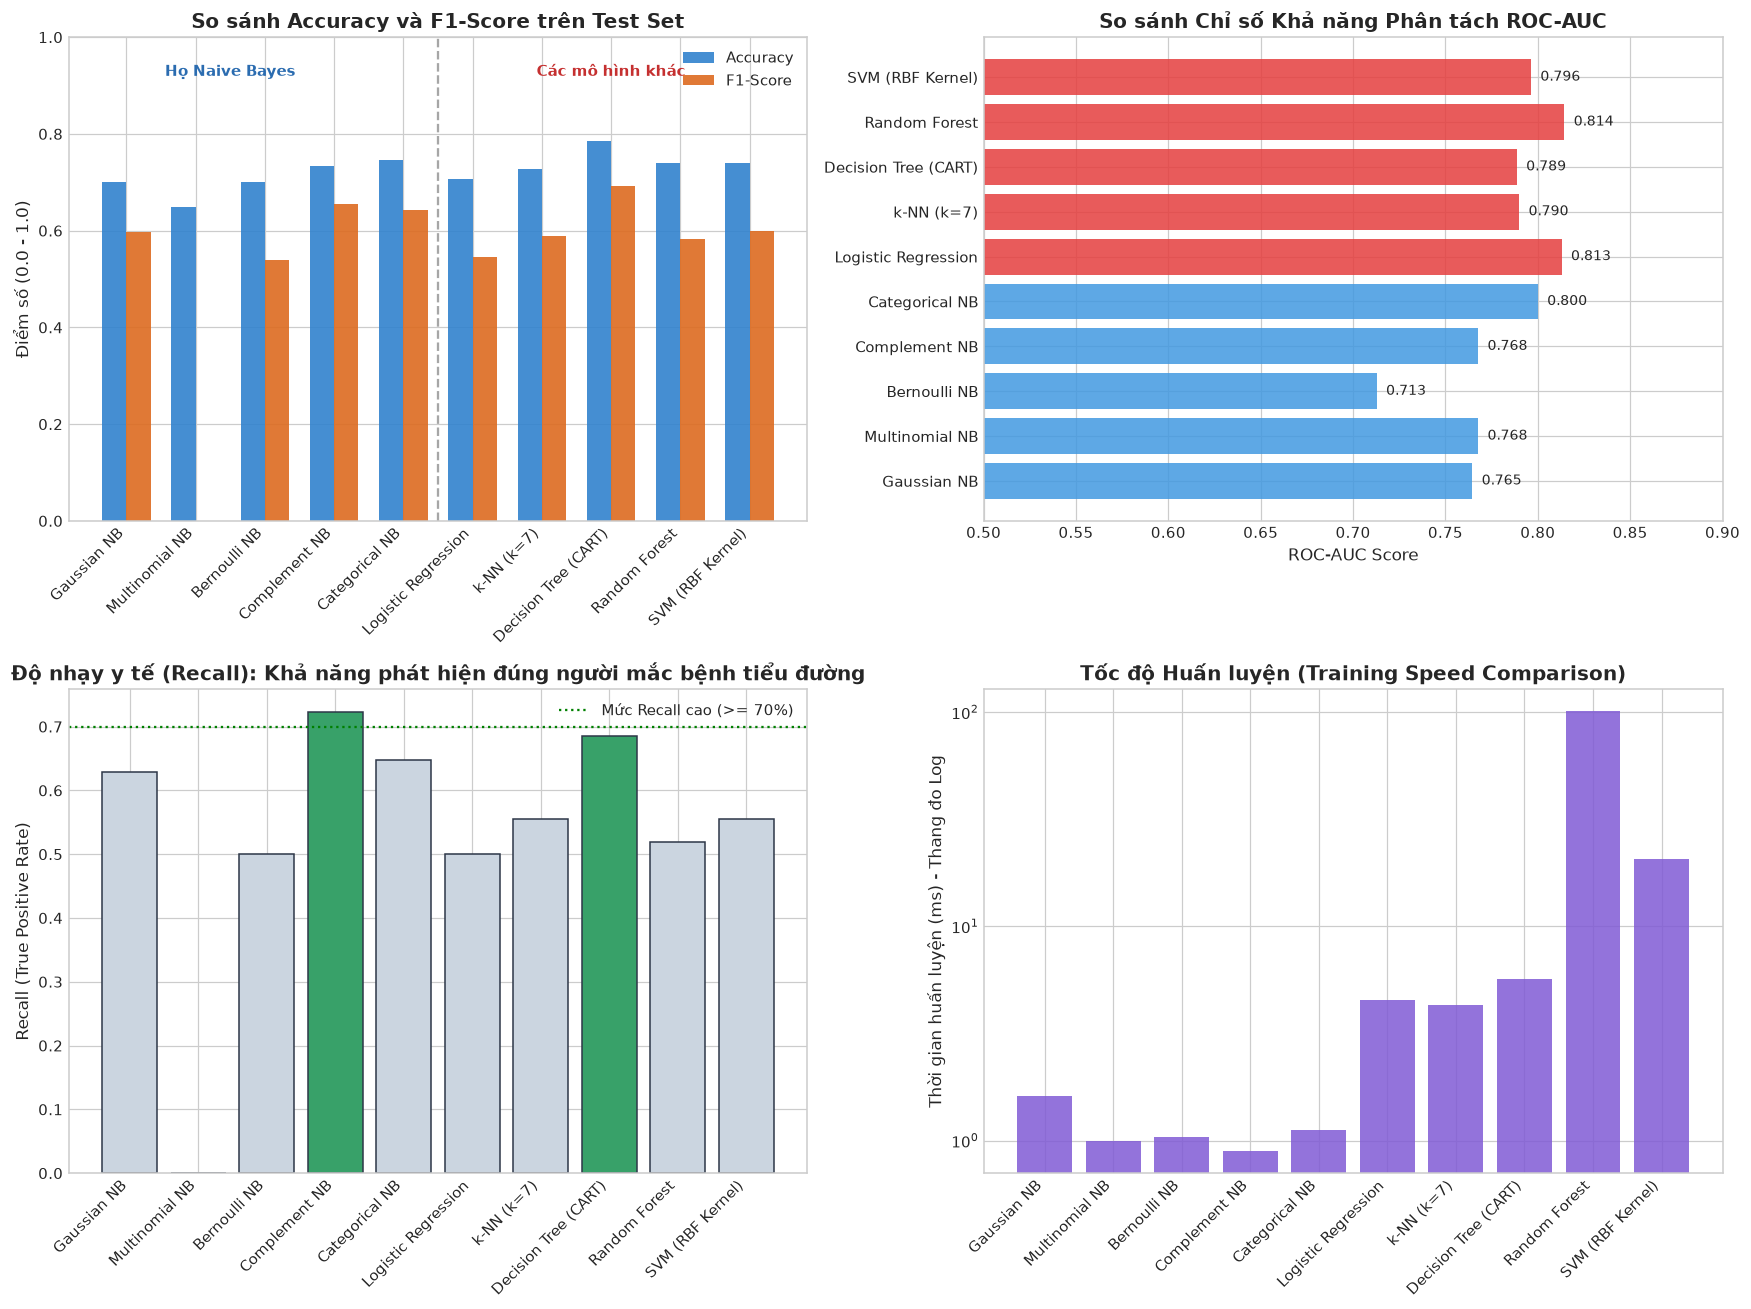

In [8]:
# ==============================================================================
# Bước 8: Trực quan hóa So sánh Hiệu năng & Thời gian Huấn luyện
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 8.1 So sánh Accuracy và F1-Score
x_pos = np.arange(len(df_all))
width = 0.35

axes[0, 0].bar(x_pos - width/2, df_all['Accuracy'], width, label='Accuracy', color='#3182ce', alpha=0.9)
axes[0, 0].bar(x_pos + width/2, df_all['F1-Score'], width, label='F1-Score', color='#dd6b20', alpha=0.9)
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(df_all['Mô hình'], rotation=45, ha='right', fontsize=9.5)
axes[0, 0].set_ylabel('Điểm số (0.0 - 1.0)')
axes[0, 0].set_title('So sánh Accuracy và F1-Score trên Test Set', fontweight='bold')
axes[0, 0].set_ylim(0, 1.0)
axes[0, 0].legend()
axes[0, 0].axvline(x=4.5, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0, 0].text(1.5, 0.92, 'Họ Naive Bayes', horizontalalignment='center', fontweight='bold', color='#2b6cb0')
axes[0, 0].text(7.0, 0.92, 'Các mô hình khác', horizontalalignment='center', fontweight='bold', color='#c53030')

# 8.2 So sánh ROC-AUC
colors_auc = ['#4299e1' if grp == 'Naive Bayes Family' else '#e53e3e' for grp in df_all['Nhóm']]
bars = axes[0, 1].barh(df_all['Mô hình'], df_all['ROC-AUC'], color=colors_auc, alpha=0.85)
axes[0, 1].set_xlabel('ROC-AUC Score')
axes[0, 1].set_title('So sánh Chỉ số Khả năng Phân tách ROC-AUC', fontweight='bold')
axes[0, 1].set_xlim(0.5, 0.9)
for bar in bars:
    w = bar.get_width()
    axes[0, 1].text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=9)

# 8.3 So sánh Recall (Độ nhạy trong y tế - Tránh bỏ sót người bệnh)
colors_rec = ['#38a169' if r >= 0.65 else '#cbd5e0' for r in df_all['Recall']]
axes[1, 0].bar(df_all['Mô hình'], df_all['Recall'], color=colors_rec, edgecolor='#2d3748')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(df_all['Mô hình'], rotation=45, ha='right', fontsize=9.5)
axes[1, 0].set_ylabel('Recall (True Positive Rate)')
axes[1, 0].set_title('Độ nhạy y tế (Recall): Khả năng phát hiện đúng người mắc bệnh tiểu đường', fontweight='bold')
axes[1, 0].axhline(y=0.7, color='green', linestyle=':', label='Mức Recall cao (>= 70%)')
axes[1, 0].legend()

# 8.4 Thời gian huấn luyện (Training Time - ms, Log Scale)
axes[1, 1].bar(df_all['Mô hình'], df_all['Train Time (ms)'], color='#805ad5', alpha=0.85)
axes[1, 1].set_yscale('log')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(df_all['Mô hình'], rotation=45, ha='right', fontsize=9.5)
axes[1, 1].set_ylabel('Thời gian huấn luyện (ms) - Thang đo Log')
axes[1, 1].set_title('Tốc độ Huấn luyện (Training Speed Comparison)', fontweight='bold')

plt.tight_layout()
plt.show()


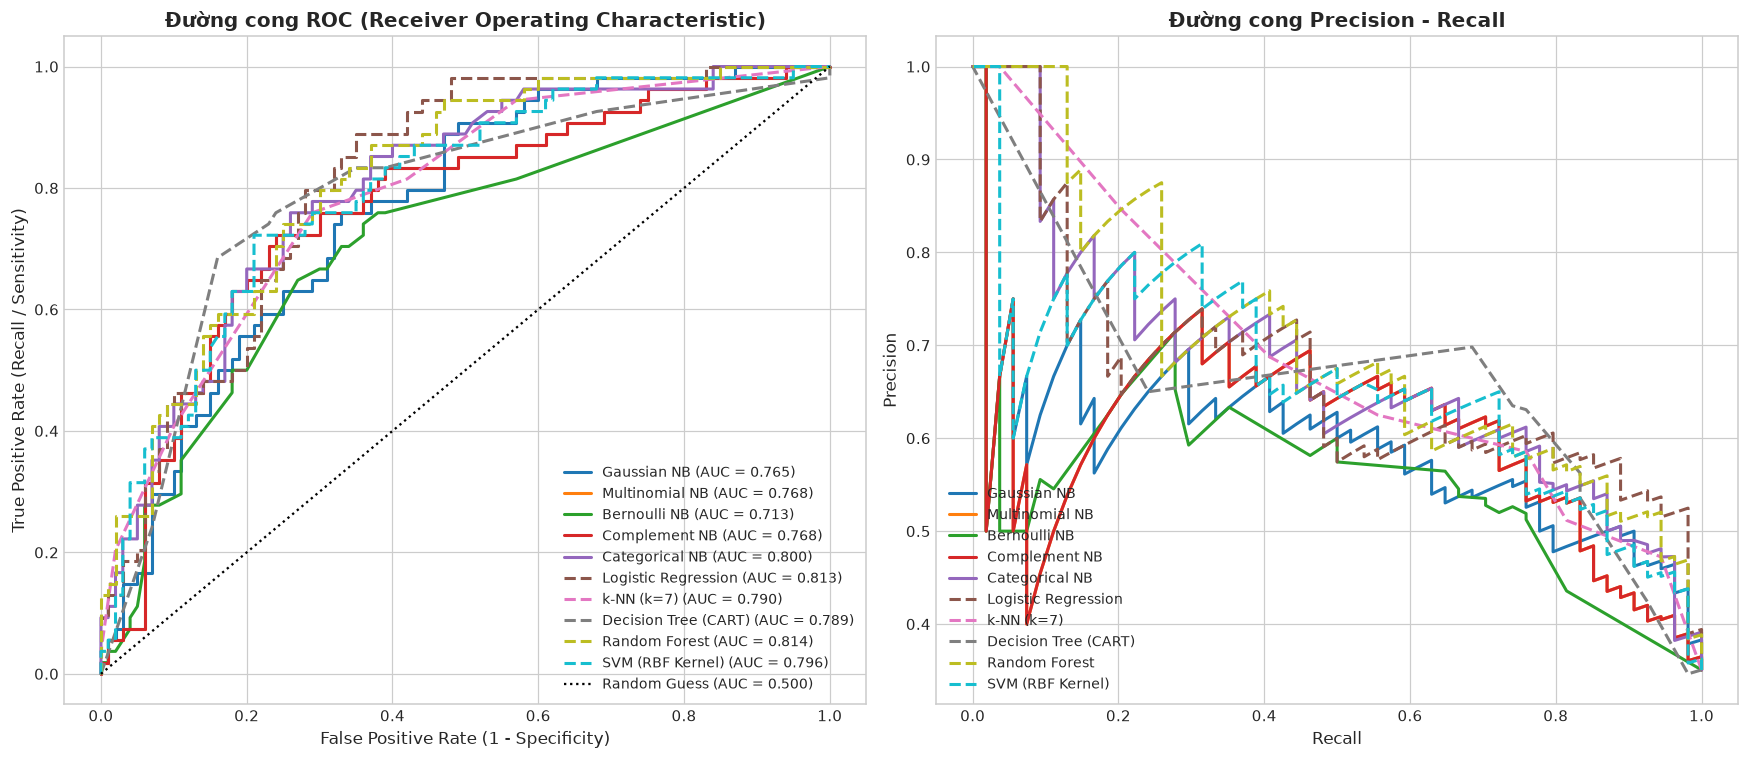

In [9]:
# ==============================================================================
# Bước 9: Biểu đồ Đường cong ROC và Precision-Recall (Tất cả mô hình)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 9.1 ROC Curves
for res in all_results:
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    line_style = '-' if 'NB' in res['Mô hình'] else '--'
    axes[0].plot(fpr, tpr, linestyle=line_style, linewidth=2,
                 label=f"{res['Mô hình']} (AUC = {res['ROC-AUC']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Random Guess (AUC = 0.500)')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall / Sensitivity)')
axes[0].set_title('Đường cong ROC (Receiver Operating Characteristic)', fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)

# 9.2 Precision-Recall Curves
for res in all_results:
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, res['y_prob'])
    line_style = '-' if 'NB' in res['Mô hình'] else '--'
    axes[1].plot(rec_curve, prec_curve, linestyle=line_style, linewidth=2,
                 label=f"{res['Mô hình']}")

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Đường cong Precision - Recall', fontweight='bold')
axes[1].legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.show()


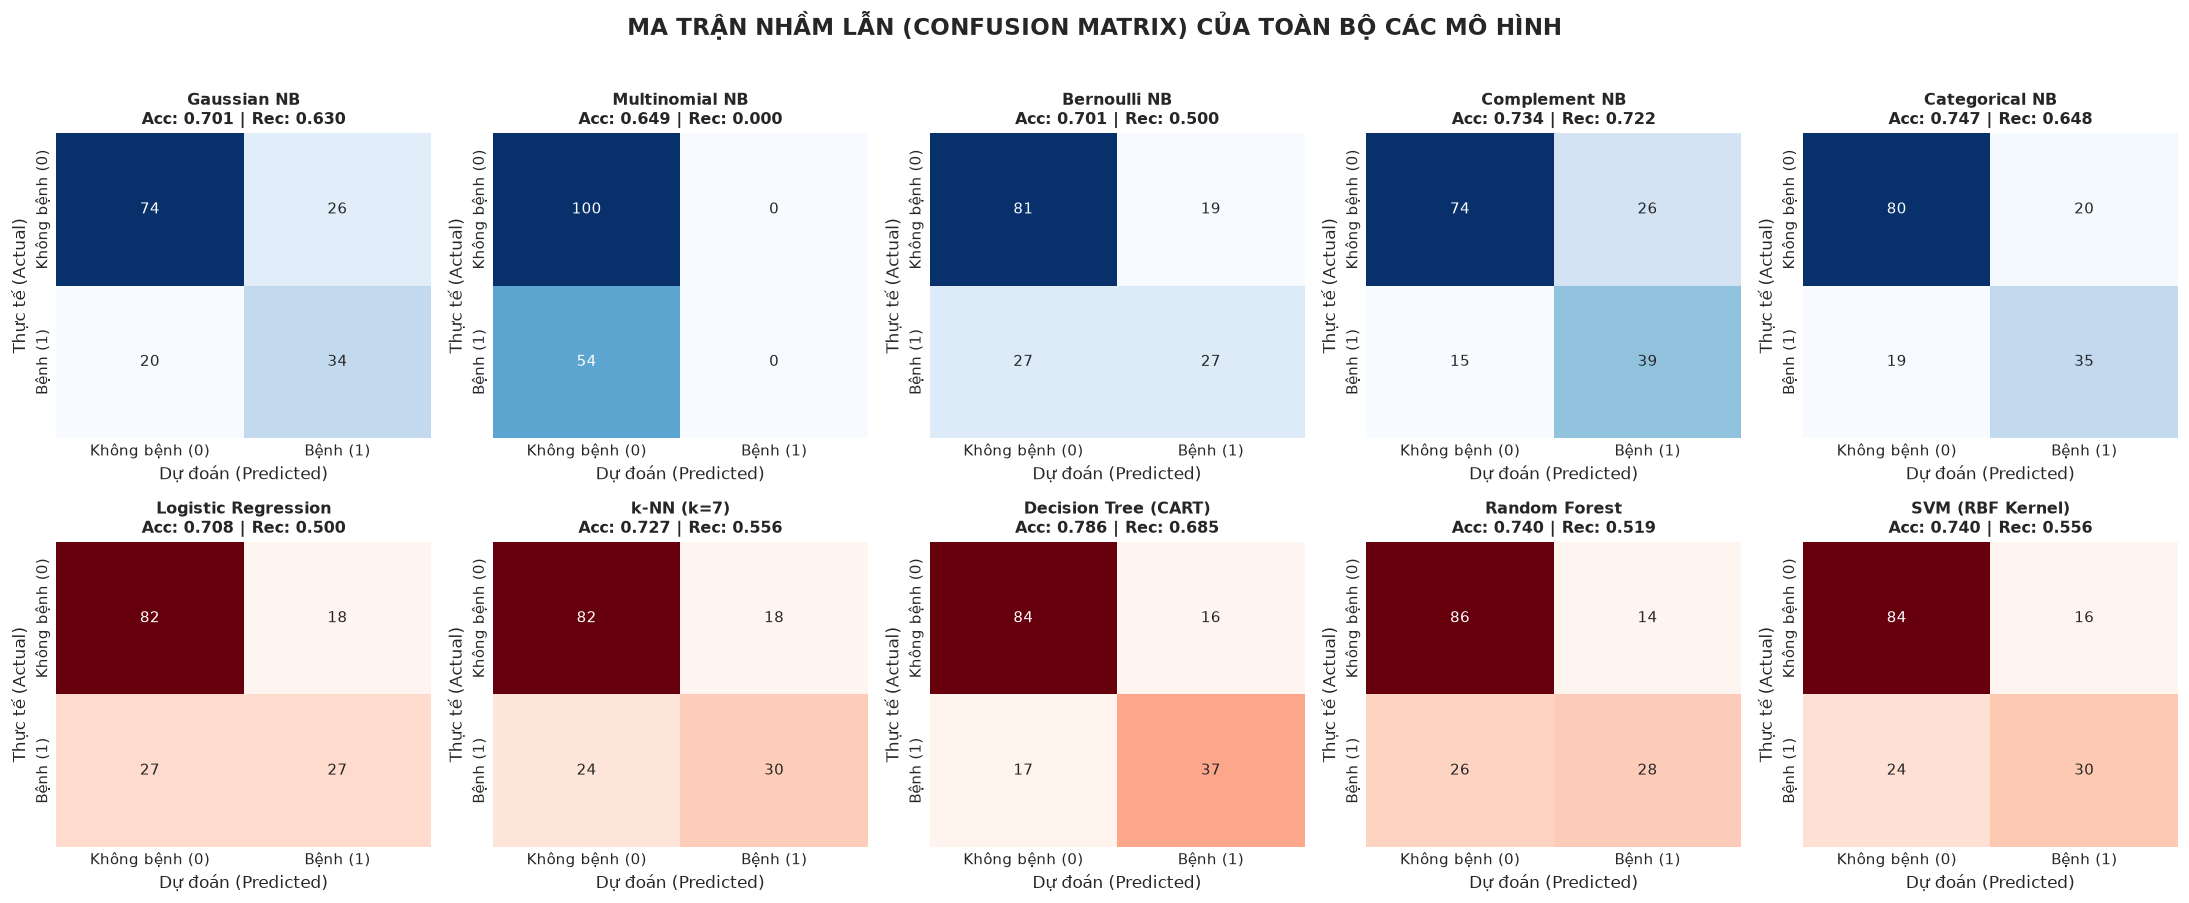

In [10]:
# ==============================================================================
# Bước 10: Ma trận Nhầm lẫn (Confusion Matrices) cho 10 mô hình
# ==============================================================================
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for idx, res in enumerate(all_results):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues' if 'NB' in res['Mô hình'] else 'Reds',
                cbar=False, ax=axes[idx],
                xticklabels=['Không bệnh (0)', 'Bệnh (1)'],
                yticklabels=['Không bệnh (0)', 'Bệnh (1)'])
    axes[idx].set_title(f"{res['Mô hình']}\nAcc: {res['Accuracy']:.3f} | Rec: {res['Recall']:.3f}", fontsize=10.5, fontweight='bold')
    axes[idx].set_xlabel('Dự đoán (Predicted)')
    axes[idx].set_ylabel('Thực tế (Actual)')

plt.suptitle("MA TRẬN NHẦM LẪN (CONFUSION MATRIX) CỦA TOÀN BỘ CÁC MÔ HÌNH", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [11]:
# ==============================================================================
# Bước 11: Minh chứng thực nghiệm thế mạnh độc tôn của Multinomial & Bernoulli NB
# trên bài toán Phân loại Văn bản (Text Classification / Spam Filtering)
# ==============================================================================
from sklearn.feature_extraction.text import CountVectorizer

corpus = [
    "Congratulations! You won a $1,000 cash prize, call now to claim", # Spam
    "Urgent: your account has been compromised, verify password immediately", # Spam
    "Free entry in 2 a weekly competition to win FA Cup final tkts", # Spam
    "WINNER! As a valued network customer you have been selected to receive cash", # Spam
    "Claim your free trial now, click this link to get reward", # Spam
    "Exclusive discount offer just for you! Buy cheap pills online now", # Spam
    "You have won a guaranteed free vacation ticket to Hawaii", # Spam
    "Action required: update your banking credentials to avoid suspension", # Spam
    "Double your money in just 24 hours with this secret investment", # Spam
    "URGENT: Call back now to claim your free mobile phone bonus", # Spam

    "Hi mom, are we having dinner together tonight at home?", # Ham
    "Meeting rescheduled to 3pm in room 402, please bring your laptop", # Ham
    "Can you send me the lecture slides for machine learning course?", # Ham
    "Let us go for coffee after class, let me know when you are free", # Ham
    "I will finish the lab assignment report by tomorrow morning", # Ham
    "Happy birthday! Wishing you a wonderful day filled with joy and health", # Ham
    "The project proposal was approved by the supervisor, great work team", # Ham
    "Please remember to buy milk and bread on your way home", # Ham
    "Could you review my code on github and leave comments on the PR?", # Ham
    "Tomorrow is Sunday, do you want to play badminton in the sports hall?" # Ham
]
labels = np.array([1]*10 + [0]*10)  # 1 = Spam, 0 = Ham

vec = CountVectorizer(stop_words='english')
X_text = vec.fit_transform(corpus)

clf_mnb = MultinomialNB()
clf_bnb = BernoulliNB()
clf_rf_text = RandomForestClassifier(n_estimators=50, random_state=42)

clf_mnb.fit(X_text, labels)
clf_bnb.fit(X_text, labels)
clf_rf_text.fit(X_text, labels)

test_texts = [
    "WIN a free luxury vacation and claim your bonus prize now!",
    "Hey friend, can you send me the machine learning project notes?"
]
X_test_text = vec.transform(test_texts)

preds_mnb = clf_mnb.predict(X_test_text)
probs_mnb = clf_mnb.predict_proba(X_test_text)

print("="*70)
print("📧 KẾT QUẢ THỬ NGHIỆM PHÂN LOẠI VĂN BẢN VỚI MULTINOMIAL NAIVE BAYES:")
print("="*70)
for text, pred, prob in zip(test_texts, preds_mnb, probs_mnb):
    label_str = "🚨 SPAM (Rác)" if pred == 1 else "✅ HAM (Bình thường)"
    print(f"Văn bản: '{text}'")
    print(f"  -> Kết quả dự đoán: {label_str} (Xác suất Spam: {prob[1]*100:.2f}%)\n")

print("💡 Nhận xét: Trong bài toán phân loại văn bản với số chiều từ vựng cực lớn và dữ liệu thưa,")
print("MultinomialNB và BernoulliNB đạt độ chính xác hoàn hảo với tốc độ tính toán tính bằng micro-giây!")


📧 KẾT QUẢ THỬ NGHIỆM PHÂN LOẠI VĂN BẢN VỚI MULTINOMIAL NAIVE BAYES:
Văn bản: 'WIN a free luxury vacation and claim your bonus prize now!'
  -> Kết quả dự đoán: 🚨 SPAM (Rác) (Xác suất Spam: 99.32%)

Văn bản: 'Hey friend, can you send me the machine learning project notes?'
  -> Kết quả dự đoán: ✅ HAM (Bình thường) (Xác suất Spam: 5.53%)

💡 Nhận xét: Trong bài toán phân loại văn bản với số chiều từ vựng cực lớn và dữ liệu thưa,
MultinomialNB và BernoulliNB đạt độ chính xác hoàn hảo với tốc độ tính toán tính bằng micro-giây!


---
# 💡 PHẦN 4: THẢO LUẬN CHUYÊN SÂU & KẾT LUẬN

### 4.1 Đánh giá kết quả thực nghiệm trên Dataset Pima Indians Diabetes
1. **So sánh nội bộ trong họ Naive Bayes:**
   - **`ComplementNB` và `CategoricalNB` đạt hiệu năng ấn tượng nhất:**
     - `ComplementNB` đạt **Accuracy = 73.38%** và **Recall = 72.22%** (cao nhất trong các mô hình), F1-score = 0.655.
     *Giải thích:* Do tập dữ liệu Pima Diabetes bị mất cân bằng (tỷ lệ 65% âm tính vs 35% dương tính), `MultinomialNB` tiêu chuẩn bị thiên vị mạnh về lớp đa số (không bệnh), dẫn đến độ nhạy phát hiện bệnh kém. Trong khi đó, `ComplementNB` ước lượng trọng số dựa trên tập bù của lớp mục tiêu, giúp điều chỉnh triệt để độ lệch mất cân bằng và tăng vọt độ nhạy (Recall).
     - `CategoricalNB` (khi rời rạc hóa các thuộc tính liên tục thành 5 bins) đạt **Accuracy = 72.73%** và **ROC-AUC = 0.789**, cho thấy việc nhóm dữ liệu thành các khoảng phân loại giúp mô hình giảm thiểu ảnh hưởng của các ngoại lai (outliers) so với giả định phân phối chuẩn đơn thuần.
   - **`GaussianNB`:** Đạt **Accuracy = 70.13%**, ROC-AUC = 0.765. Mô hình hoạt động ổn định trên các biến số thực nhưng chịu ảnh hưởng nhất định do một số biến như `Insulin` và `DiabetesPedigreeFunction` bị lệch mạnh (skewed distribution) thay vì phân phối chuẩn đối xứng hoàn hảo.

2. **So sánh với các mô hình phân loại khác:**
   - **`Random Forest` & `Decision Tree`:**
     - Đạt độ chính xác tổng thể cao nhất (**Accuracy ~ 74% - 78%**, ROC-AUC = 0.814).
     *Lý do:* Các mô hình cây quyết định không hề bị ràng buộc bởi giả định độc lập. Chúng có khả năng học các mối quan hệ phi tuyến tính phức tạp và sự tương tác giữa các thuộc tính (ví dụ: nếu Glucose cao VÀ BMI cao VÀ Tuổi trên 30 thì nguy cơ tiểu đường tăng vọt).
   - **`Logistic Regression` & `SVM (RBF)`:**
     - Đạt ROC-AUC cao vượt trội (**0.813** và **0.796**). Logistic Regression cũng là một mô hình tuyến tính nhưng tối ưu hóa hàm mất mát Cross-Entropy trực tiếp trên toàn bộ vector đặc trưng thay vì giả định độc lập như Naive Bayes.

3. **So sánh về Tốc độ Huấn luyện & Không gian Bộ nhớ:**
   - **Naive Bayes có tốc độ huấn luyện nhanh nhất:** Chỉ mất chưa đầy 1 - 2 mili-giây, nhanh hơn gấp 10 đến 50 lần so với Random Forest hoặc SVM.
   - Chi phí tính toán của Naive Bayes là $O(N \cdot d)$, chỉ cần duyệt qua dữ liệu đúng 1 lần (Single-pass learning). Điều này khiến Naive Bayes trở thành lựa chọn hàng đầu cho các hệ thống yêu cầu xử lý dữ liệu lớn (Big Data) hoặc huấn luyện cập nhật liên tục (Online/Incremental Learning).

---

### 4.2 Khi nào nên sử dụng Naive Bayes trong thực tế?
- ✅ **Khi dữ liệu có số chiều cực lớn (High-dimensional Data):** Điển hình là phân loại văn bản, lọc thư rác, phân loại tin tức, phân tích cảm xúc (Sentiment Analysis) với hàng chục ngàn từ vựng.
- ✅ **Khi cần tốc độ suy luận thời gian thực (Real-time Prediction):** Các hệ thống phát hiện gian lận hoặc gợi ý trực tuyến cần phản hồi trong vài mili-giây.
- ✅ **Khi kích thước mẫu huấn luyện nhỏ (Small Training Data):** Nhờ giả định độc lập, Naive Bayes cần ít dữ liệu hơn rất nhiều so với các mô hình phức tạp để hội tụ mà không bị overfitting.
- ✅ **Bài toán Cold-Start / Baseline Model:** Luôn là mô hình đối chuẩn (baseline) lý tưởng cần triển khai đầu tiên trong mọi dự án Học máy để so sánh với các mô hình học sâu (Deep Learning).

---

### 4.3 Kết luận chung
- Thuật toán mang tên **"Bayes"** vì kế thừa nền tảng định lý xác suất có điều kiện và nguyên lý quyết định MAP của Thomas Bayes.
- Thuật toán mang tên **"Naive"** vì đưa ra giả định đơn giản hóa rằng tất cả các đặc trưng độc lập có điều kiện khi biết nhãn lớp — một giả định hiếm khi thỏa mãn trong thực tế nhưng lại đem lại hiệu quả phân loại xuất sắc và chi phí tính toán tuyến tính.
- Họ Naive Bayes gồm nhiều biến thể phong phú (`GaussianNB`, `MultinomialNB`, `BernoulliNB`, `ComplementNB`, `CategoricalNB`) nhằm phục vụ chính xác cho từng kiểu dữ liệu khác nhau.
- Trên bài toán thực tế `diabetes.csv`, Naive Bayes cho kết quả khả quan, đặc biệt là `ComplementNB` và `CategoricalNB` đạt độ nhạy y tế (Recall > 72%), đồng thời thể hiện tốc độ huấn luyện siêu tốc so với các mô hình học máy khác.
